In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import accuracy_score, mutual_info_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import KFold, cross_val_score


In [2]:
data = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
# checking for missin values
data.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
# check data types for data preparation
data.dtypes

# categorical features missing values replacement
data = data.fillna({
    col: 'NA'
    for col in data.select_dtypes(include=['object', 'string']).columns
})

# numerical features missing values replacement
data = data.fillna({
    col: 0.0
    for col in data.select_dtypes(include=['number']).columns
})

In [5]:
# splitting the data
data_full_train, data_test = train_test_split(data, test_size=0.2, random_state=1)

data_train, data_val = train_test_split(
    data_full_train, test_size=0.25, random_state=1)

In [6]:
# splitting Y data
y_full_train = data_full_train["converted"].values.copy()
y_train = data_train["converted"].values.copy()
y_val = data_val["converted"].values.copy()
y_test = data_test["converted"].values.copy()

In [7]:
# Evaluating features
for num in data_train.select_dtypes(include='number').columns:
    if num == 'converted':
        continue
    auc = roc_auc_score(data_train['converted'], data_train[num])
    if auc < 0.5:
        auc = roc_auc_score(data_train['converted'], -data_train[num])
    print(f"{num}: AUC: {auc:.3f}")


annual_income: AUC: 0.608
number_of_courses_viewed: AUC: 0.723
interaction_count: AUC: 0.765
lead_score: AUC: 0.788


In [8]:
for d in (data_train, data_val, data_test):
    d.drop(columns=["converted"], inplace=True)

In [9]:
# Question 2: Training the model
# Convert DataFrame rows into dictionaries
dv = DictVectorizer(sparse=False)
train_dict = data_train.to_dict(orient="records")

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(data_val.to_dict(orient="records"))
X_test = dv.transform(data_test.to_dict(orient="records"))

In [10]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_val)

acc_full = accuracy_score(y_val, y_pred)
print("val accuracy:", round(acc_full, 2), "raw:", acc_full)

# ROC-AUC: use predicted probabilities
y_proba = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_proba)
print(f"Test ROC-AUC: {auc:.3f}")

val accuracy: 0.65 raw: 0.651
Test ROC-AUC: 0.732


In [11]:
# Question 3: Precision and Recall
result_thredhold, result_precision, result_recall, result_f1 = [], [], [], []
for threshold in np.arange(0.0, 1.0, 0.01):
    y_pred = (y_proba >= threshold).astype(int)
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)
    result_thredhold.append(threshold)
    result_precision.append(precision)
    result_recall.append(recall)
    result_f1.append(f1)


# Intersection: smallest |precision - recall|, ignoring P=R=0
best_t, best_diff = None, None
for t, p, r in zip(result_thredhold, result_precision, result_recall):
    if p == 0 and r == 0:
        continue
    d = abs(p - r)
    if best_diff is None or d < best_diff:
        best_diff, best_t = d, t
print(f"Intersection threshold: {best_t:.2f}")


Intersection threshold: 0.63


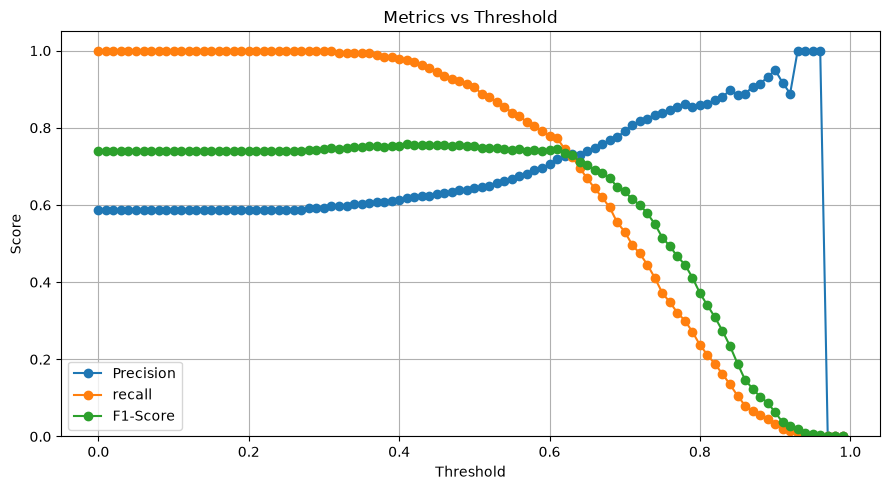

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(result_thredhold, result_precision, marker="o", label="Precision")
plt.plot(result_thredhold, result_recall, marker="o", label="recall")
plt.plot(result_thredhold, result_f1, marker="o", label="F1-Score")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Metrics vs Threshold")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [13]:
# Question 4: F1 score
thredhold_result, result_P, result_R, result_F1 = [], [], [], []

for threshold in np.arange(0.0, 1.0, 0.01):
    y_pred = (y_proba >= threshold).astype(int)
    P = precision_score(y_val, y_pred)
    R = recall_score(y_val, y_pred)
    if P + R == 0:
        F1 = 0
    else:
        F1 = 2 * (P * R) / (P + R)
    
    thredhold_result.append(threshold)
    result_P.append(P)
    result_R.append(R)
    result_F1.append(F1)

best_idx = int(np.argmax(result_F1))
print(f"Max F1={result_F1[best_idx]:.3f} at threshold={thredhold_result[best_idx]:.2f}")


Max F1=0.758 at threshold=0.41


/home/biohacker24/proyectos/machine-learning/zoomcamp/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/biohacker24/proyectos/machine-learning/zoomcamp/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/biohacker24/proyectos/machine-learning/zoomcamp/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this b

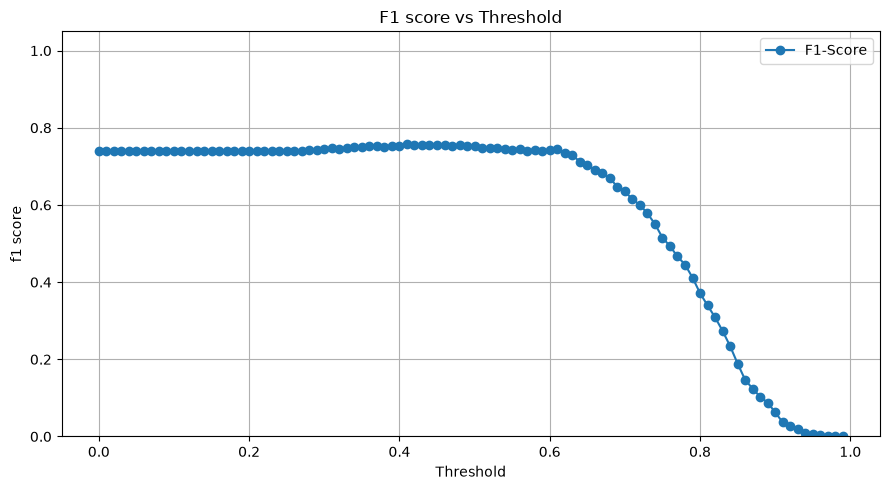

In [14]:
plt.figure(figsize=(9, 5))
plt.plot(thredhold_result, result_F1, marker="o", label="F1-Score")

plt.xlabel("Threshold")
plt.ylabel("f1 score")
plt.title("F1 score vs Threshold")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [15]:
# Question 5: 5fold 

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

auc_results = []

for train_idx, val_idx in kfold.split(data_full_train):
    df_train = data_full_train.iloc[train_idx]
    df_val = data_full_train.iloc[val_idx]
    
    y_train = df_train['converted'].copy()
    y_val = df_val['converted'].copy()

    X_train = df_train.drop(columns=["converted"])
    X_val = df_val.drop(columns=["converted"])
    
    train_dict = X_train.to_dict(orient="records")
    val_dict = X_val.to_dict(orient="records")
    
    X_train = dv.fit_transform(train_dict)
    X_val = dv.transform(val_dict)




    
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    acc_full = accuracy_score(y_val, y_pred)
    print("val accuracy:", round(acc_full, 2), "raw:", acc_full)
    
    # ROC-AUC: use predicted probabilities
    y_proba = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_proba)
    auc_results.append(auc)
    print(f"Test ROC-AUC: {auc:.3f}")

val accuracy: 0.65 raw: 0.6475
Test ROC-AUC: 0.731


val accuracy: 0.64 raw: 0.6375
Test ROC-AUC: 0.730
val accuracy: 0.67 raw: 0.67375
Test ROC-AUC: 0.736
val accuracy: 0.67 raw: 0.6725
Test ROC-AUC: 0.741
val accuracy: 0.68 raw: 0.67625
Test ROC-AUC: 0.721


In [16]:
# standar desviation
np.std(auc_results
      )

np.float64(0.006853233151022138)

In [17]:
# Question 6: Hyperparameter Tuning
for C in [0.000001, 0.001, 1]:
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    auc_results = []

    for train_idx, val_idx in kfold.split(data_full_train):
        df_train = data_full_train.iloc[train_idx]
        df_val = data_full_train.iloc[val_idx]

        y_train = df_train['converted'].copy()
        y_val = df_val['converted'].copy()

        X_train = df_train.drop(columns=["converted"])
        X_val = df_val.drop(columns=["converted"])

        train_dict = X_train.to_dict(orient="records")
        val_dict = X_val.to_dict(orient="records")

        X_train = dv.fit_transform(train_dict)
        X_val = dv.transform(val_dict)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)

        y_proba = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_proba)
        auc_results.append(auc)

    print(f"C={C}: mean={np.mean(auc_results):.3f} std={np.std(auc_results):.3f}")


C=1e-06: mean=0.617 std=0.019


C=0.001: mean=0.749 std=0.010


C=1: mean=0.732 std=0.007
